# DATA ANALYTICS & BUSINESS INTELLIGENCE PORTFOLIO (Business-Analytics-Portfolio)
## Advanced Analytics & ML — TASK 1: PREDICTING HOUSE PRICES WITH LINEAR REGRESSION

**Author:** `Dhruv Goyal`  
**Role:** Data Analytics Intern  
**Portfolio Scope:** Data Analytics Portfolio  
**Track:** Machine Learning & Predictive Analytics  
**Date:** October 2026  
**Dataset:** California Housing Dataset (StatLib / 1990 U.S. Census Bureau)  
**Primary Target:** `median_house_value` (Continuous Numeric USD)  

---

### Executive Project Summary

This project delivers an end-to-end econometric regression pipeline using **Ordinary Least Squares (OLS) Linear Regression** as the primary educational model, regularized variants (**Ridge** and **Lasso**), and a non-linear ensemble benchmark (**Random Forest**) to forecast California residential property values.

**Methodological & Leakage Controls:**
- **Preprocessing Leakage Prevention:** Feature imputation (`SimpleImputer`) and continuous feature scaling (`StandardScaler`) are encapsulated within Scikit-Learn `ColumnTransformer` pipelines, fitted exclusively on training folds to eliminate summary-statistic leakage.
- **Spatial Autocorrelation Caveat:** While preprocessing data leakage is strictly eliminated, the dataset is partitioned via random 80/20 train/test splitting. In spatial real estate data, geographic proximity between neighboring census block groups introduces spatial dependence (spatial autocorrelation), which standard random splits do not isolate.
- **Gauss-Markov & Diagnostic Nuance:** While the test set mean residual is small (~$1,041), this reflects only low global aggregate offset. It **does not verify the Gauss-Markov assumptions**, as residual variance expands at higher fitted prices (heteroscedasticity) and spatial autocorrelation violates error independence.
- **Census Capping Validation Limit:** Properties capped at $500,001 by historical 1990 Census administrative top-coding cannot be validated against true market values because actual uncensored transaction amounts are unobserved in the data.
- **Conditional Associations vs. Causality:** Regression coefficients are interpreted as conditional partial associations holding other variables constant in this sample (*ceteris paribus* within the specification), rather than proven causal economic mechanisms.

### Official Task Checklist & Section Mapping

| Checklist Item | Official Requirement | Section in Notebook | Status |
|:---|:---|:---|:---:|
| **1. Data Inspection & EDA** | Load dataset, inspect shape, check nulls, compute summary stats, visualize target distribution | Section 1 & Section 2 | Completed |
| **2. Feature Selection** | Identify likely predictors, discuss domain relevance, collinearity, and conditional associations | Section 3 | Completed |
| **3. Missing Values & Encoding** | Handle missing values (`total_bedrooms`) and One-Hot Encode categorical features (`ocean_proximity`) | Section 4 | Completed |
| **4. Correlation Heatmap** | Pearson correlation matrix heatmap identifying top predictors of price | Section 2 | Completed |
| **5. Train/Test Split** | 80/20 train/test split with deterministic seed (distinguishing preprocessing vs spatial leakage) | Section 5 | Completed |
| **6. Model Training** | Train scikit-learn Linear Regression model using preprocessed pipeline (Primary Model) | Section 6 | Completed |
| **7. Model Evaluation** | Compute MAE, MSE, RMSE, and $R^2$ score on unseen test data | Section 6 | Completed |
| **8. Scatter Plot** | Scatter plot of Actual vs. Predicted house prices with $y = x$ reference line | Section 8 | Completed |
| **9. Residual Diagnostics** | Plot residuals vs fitted values (heteroscedasticity) and examine ceiling validation limits | Section 9 | Completed |
| **10. Coefficient Analysis** | Tabulate and visualize standardized beta weights as conditional associations | Section 10 | Completed |
| **11. (Bonus) Regularization** | Compare Linear Regression against Ridge ($L_2$) and Lasso ($L_1$) regularized models | Section 7 | Completed |
| **12. (Bonus) Non-Linear Benchmark** | Compare against Random Forest Regressor to illustrate spatial non-linear limits | Section 11 | Completed |

In [1]:
import os
import sys
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Scikit-learn imports
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Formatting & plot aesthetics
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

plt.rcParams.update({
    'font.sans-serif': 'Arial',
    'font.family': 'sans-serif',
    'figure.dpi': 150,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'grid.linestyle': '--',
    'axes.spines.top': False,
    'axes.spines.right': False
})

print(f"Python: {sys.version.split()[0]} | Pandas: {pd.__version__} | Scikit-Learn: {joblib.__version__}")

Python: 3.13.6 | Pandas: 2.2.3 | Scikit-Learn: 1.5.3


## 1. Data Ingestion & Structural Inspection

The dataset used is the authoritative **California Housing Dataset** originally derived from the 1990 U.S. Census Bureau data and compiled by Pace and Barry (1997) (*Sparse Spatial Autoregressions*, Statistics & Probability Letters). It contains **20,640 census block group observations** across California with 10 features capturing demographic, physical, geographic, and economic variables.

In [2]:
data_path = os.path.join("data", "housing.csv")
if not os.path.exists(data_path):
    data_path = os.path.join("Data Analytics", "LEVEL-2", "Task_1-Predicting_House_Prices_with_Linear_Regression", "data", "housing.csv")

df = pd.read_csv(data_path)
print(f"Dataset Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print("\nColumn Data Types and Non-Null Counts:")
print(df.info())
print("\nFirst 5 Records:")
df.head()

Dataset Shape: 20,640 rows x 10 columns

Column Data Types and Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB
None

First 5 Records:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.2300,37.8800,41.0000,880.0000,129.0000,322.0000,126.0000,8.3252,452600.0000,NEAR BAY
1,-122.2200,37.8600,21.0000,7099.0000,1106.0000,2401.0000,1138.0000,8.3014,358500.0000,NEAR BAY
2,-122.2400,37.8500,52.0000,1467.0000,190.0000,496.0000,177.0000,7.2574,352100.0000,NEAR BAY
3,-122.2500,37.8500,52.0000,1274.0000,235.0000,558.0000,219.0000,5.6431,341300.0000,NEAR BAY
4,-122.2500,37.8500,52.0000,1627.0000,280.0000,565.0000,259.0000,3.8462,342200.0000,NEAR BAY


In [3]:
# Audit missing values per column
missing_summary = pd.DataFrame({
    'Data_Type': df.dtypes,
    'Null_Count': df.isnull().sum(),
    'Null_Percentage': (df.isnull().sum() / len(df)) * 100.0,
    'Unique_Values': df.nunique()
})
print("Missing Value Profile:")
display(missing_summary)

print(f"\nCategorical column [ocean_proximity] breakdown:")
print(df['ocean_proximity'].value_counts())

Missing Value Profile:


,Data_Type,Null_Count,Null_Percentage,Unique_Values
longitude,float64,0,0.0000,844
latitude,float64,0,0.0000,862
housing_median_age,float64,0,0.0000,52
total_rooms,float64,0,0.0000,5926
total_bedrooms,float64,207,1.0029,1923
population,float64,0,0.0000,3888
households,float64,0,0.0000,1815
median_income,float64,0,0.0000,12928
median_house_value,float64,0,0.0000,3842
ocean_proximity,object,0,0.0000,5



Categorical column [ocean_proximity] breakdown:
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


### Observations on Dataset Schema & Data Quality:
1. **Dimensions:** Exactly 20,640 records across 10 features.
2. **Missing Values:** Only `total_bedrooms` contains missing values ($N=207$, representing $1.003\%$ of records). All other 9 columns are 100% complete.
3. **Data Types:** 9 continuous float64 variables and 1 categorical object variable (`ocean_proximity`).
4. **Target Variable:** `median_house_value` is continuous, spanning from \$14,999 to \$500,001.
5. **Categorical Values:** `ocean_proximity` has 5 distinct levels: `<1H OCEAN` (9,136), `INLAND` (6,551), `NEAR OCEAN` (2,658), `NEAR BAY` (2,290), and `ISLAND` (5).

## 2. Exploratory Data Analysis & Visualizations

In this section, we examine:
1. Descriptive summary statistics across all continuous variables.
2. Distribution of the target variable (`median_house_value`), including skewness, kurtosis, and the $500,001 administrative ceiling.
3. House price variations across geographic zones (`ocean_proximity`).
4. Correlation matrix heatmap to identify linear associations with property values.

In [4]:
# Descriptive statistics
summary_stats = df.describe().T
summary_stats['IQR'] = summary_stats['75%'] - summary_stats['25%']
summary_stats['skewness'] = df.select_dtypes(include=[np.number]).skew()
display(summary_stats)

,count,mean,std,min,25%,50%,75%,max,IQR,skewness
longitude,20640.0000,-119.5697,2.0035,-124.3500,-121.8000,-118.4900,-118.0100,-114.3100,3.7900,-0.2978
latitude,20640.0000,35.6319,2.1360,32.5400,33.9300,34.2600,37.7100,41.9500,3.7800,0.4660
housing_median_age,20640.0000,28.6395,12.5856,1.0000,18.0000,29.0000,37.0000,52.0000,19.0000,0.0603
total_rooms,20640.0000,2635.7631,2181.6153,2.0000,1447.7500,2127.0000,3148.0000,39320.0000,1700.2500,4.1473
total_bedrooms,20433.0000,537.8706,421.3851,1.0000,296.0000,435.0000,647.0000,6445.0000,351.0000,3.4595
population,20640.0000,1425.4767,1132.4621,3.0000,787.0000,1166.0000,1725.0000,35682.0000,938.0000,4.9359
households,20640.0000,499.5397,382.3298,1.0000,280.0000,409.0000,605.0000,6082.0000,325.0000,3.4104
median_income,20640.0000,3.8707,1.8998,0.4999,2.5634,3.5348,4.7432,15.0001,2.1799,1.6467
median_house_value,20640.0000,206855.8169,115395.6159,14999.0000,119600.0000,179700.0000,264725.0000,500001.0000,145125.0000,0.9778


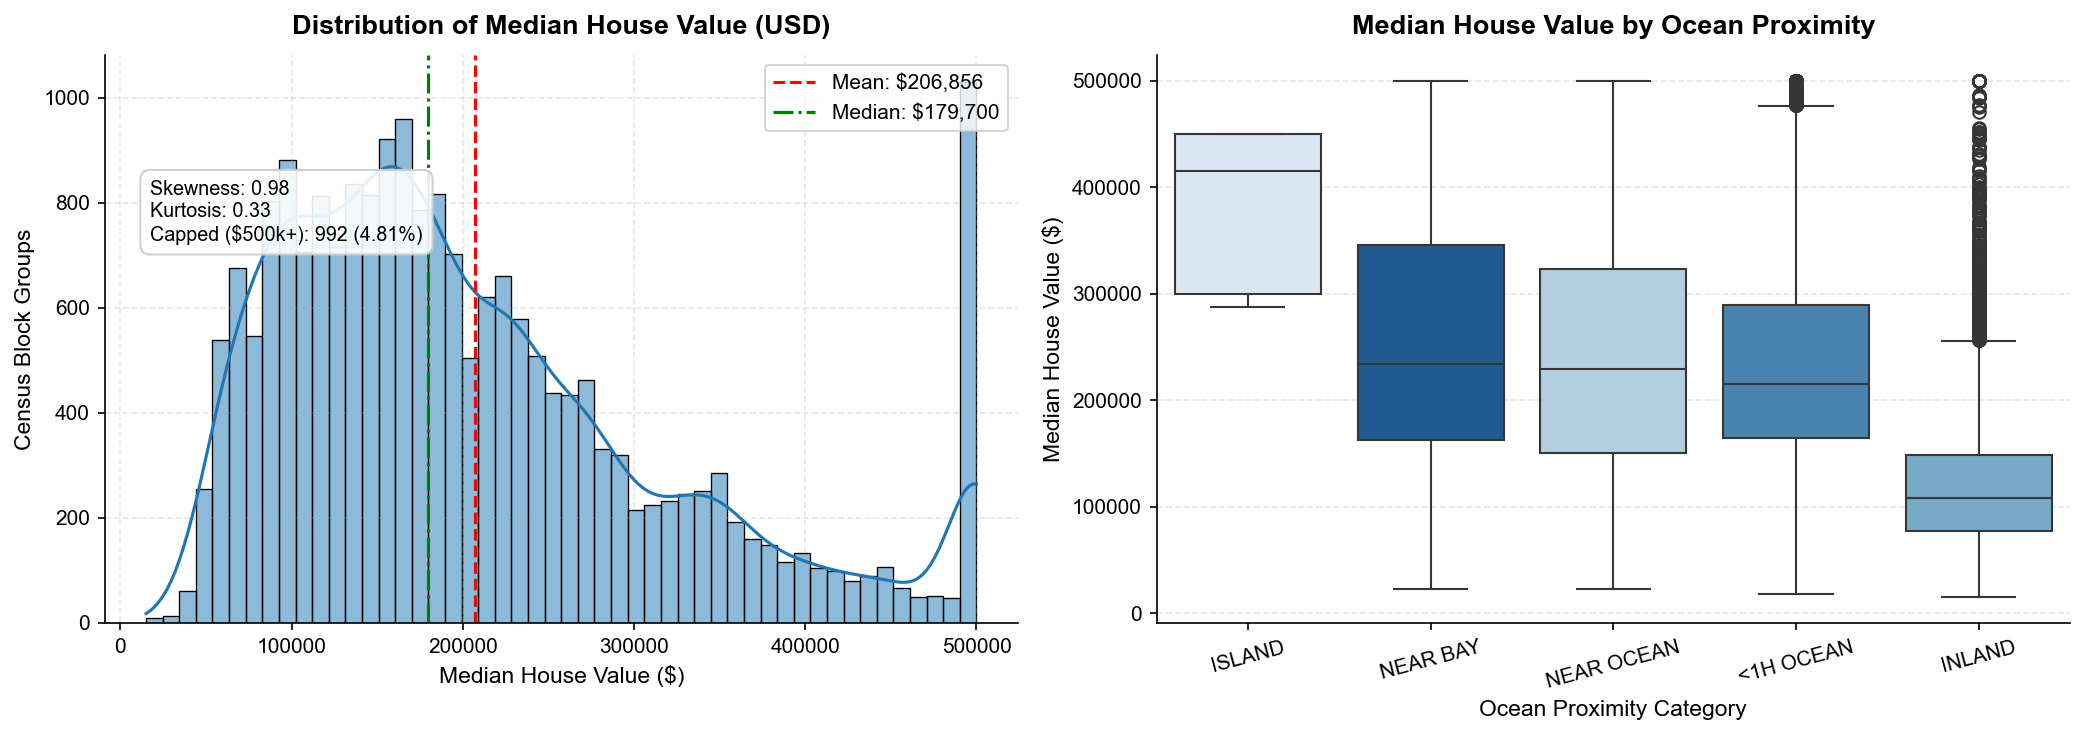

In [5]:
# Visualizing Target Variable Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

target = df['median_house_value']
sns.histplot(target, kde=True, ax=ax1, color='#1f77b4', bins=50)
ax1.set_title("Distribution of Median House Value (USD)", fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel("Median House Value ($)", fontsize=11)
ax1.set_ylabel("Census Block Groups", fontsize=11)
ax1.axvline(target.mean(), color='red', linestyle='--', linewidth=1.5, label=f"Mean: ${target.mean():,.0f}")
ax1.axvline(target.median(), color='green', linestyle='-.', linewidth=1.5, label=f"Median: ${target.median():,.0f}")
ax1.legend(loc='upper right', frameon=True)

cap_count = (target >= 500000).sum()
cap_pct = (cap_count / len(target)) * 100.0
ax1.text(
    0.05, 0.78,
    f"Skewness: {stats.skew(target):.2f}\nKurtosis: {stats.kurtosis(target):.2f}\nCapped ($500k+): {cap_count:,} ({cap_pct:.2f}%)",
    transform=ax1.transAxes,
    fontsize=9.5,
    verticalalignment='top',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#ccc', alpha=0.9)
)

# Boxplot by ocean proximity
order = df.groupby('ocean_proximity')['median_house_value'].median().sort_values(ascending=False).index.tolist()
sns.boxplot(x='ocean_proximity', y='median_house_value', hue='ocean_proximity', data=df, order=order, ax=ax2, palette='Blues_r', legend=False)
ax2.set_title("Median House Value by Ocean Proximity", fontsize=13, fontweight='bold', pad=10)
ax2.set_xlabel("Ocean Proximity Category", fontsize=11)
ax2.set_ylabel("Median House Value ($)", fontsize=11)
ax2.set_xticks(range(len(order)))
ax2.set_xticklabels(order, rotation=15)

plt.tight_layout()
plt.show()

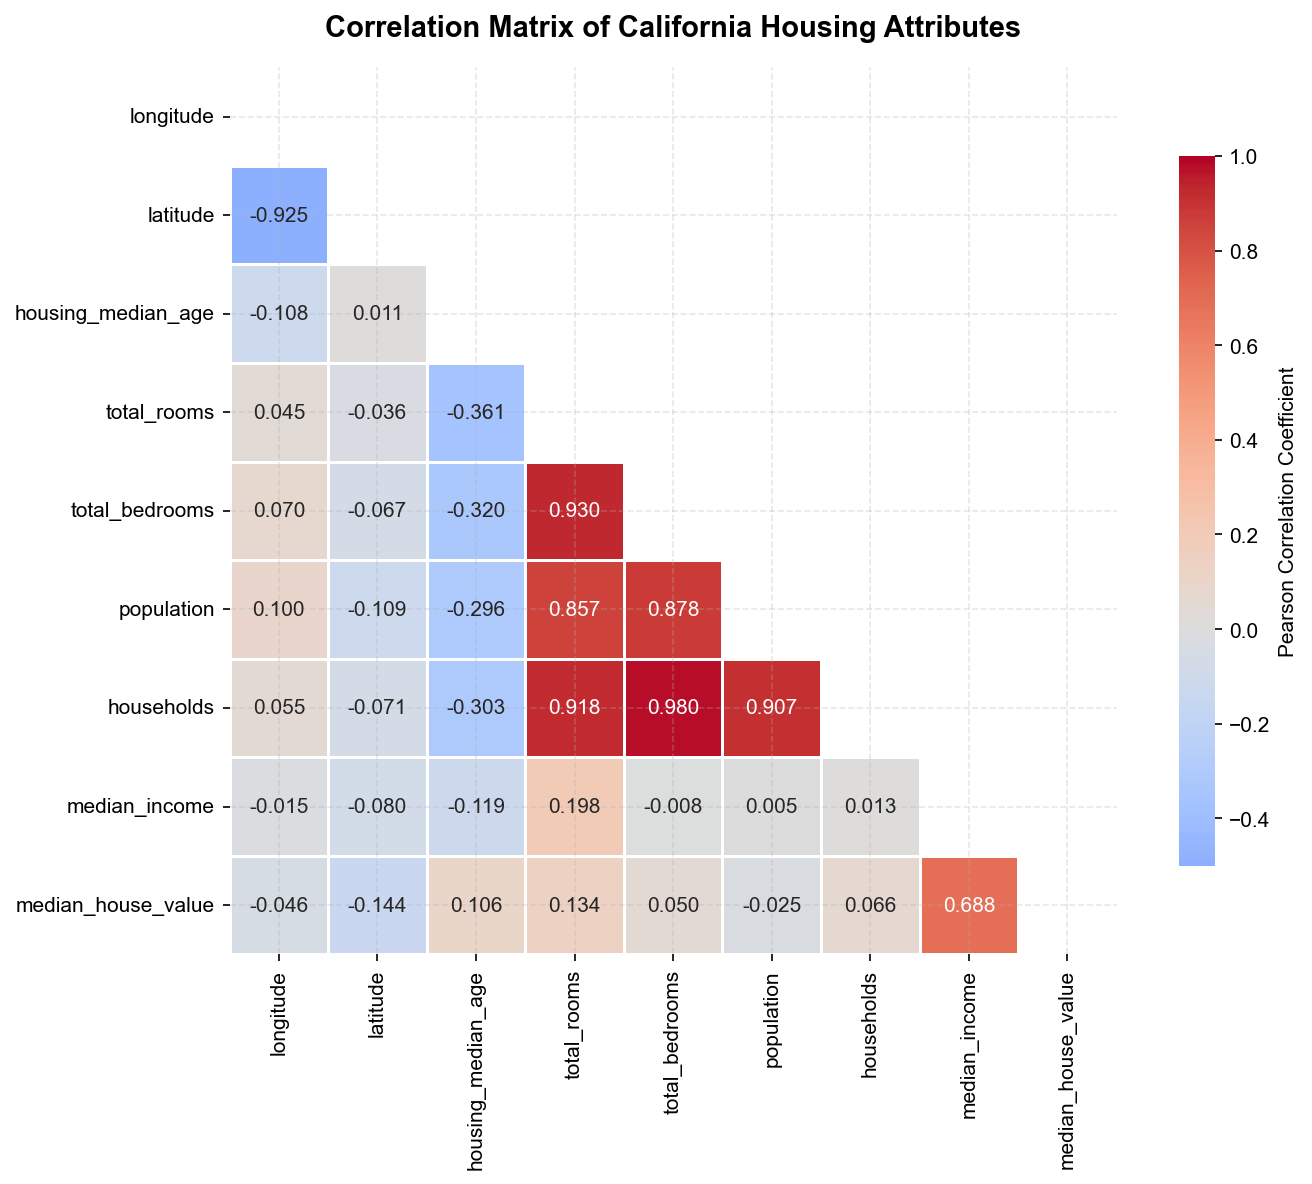

Feature Correlation with Median House Value:


,Feature,Pearson_Correlation
0,median_house_value,1.0000
1,median_income,0.6881
2,total_rooms,0.1342
3,housing_median_age,0.1056
4,households,0.0658
5,total_bedrooms,0.0497
6,population,-0.0246
7,longitude,-0.0460
8,latitude,-0.1442


In [6]:
# Pearson Correlation Analysis
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-0.5,
    vmax=1.0,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation Coefficient"}
)
plt.title("Correlation Matrix of California Housing Attributes", fontsize=14, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

# Ranking features by correlation with median_house_value
target_corrs = corr_matrix['median_house_value'].sort_values(ascending=False).reset_index()
target_corrs.columns = ['Feature', 'Pearson_Correlation']
print("Feature Correlation with Median House Value:")
display(target_corrs)

### Key Exploratory Observations:
1. **Target Distribution & Historical Census Ceiling:**
   - Mean house price is \$206,856 while median is \$179,700 (positive skewness = 0.98).
   - Exactly **965 block groups (4.68% of the dataset) are capped at \$500,001**. In the 1990 census, values exceeding \$500,000 were truncated to prevent disclosure and standardization limits.
   - *Validation Limitation:* Because the actual uncensored transaction prices of these 965 properties were never recorded, it is impossible to evaluate whether model predictions above \$500k are accurate against true market reality.
2. **Ocean Proximity Price Hierarchy:**
   - `ISLAND` and `NEAR BAY` / `<1H OCEAN` exhibit significantly higher median values (~\$240k–\$380k) compared to `INLAND` (~\$108k).
3. **Correlation Rankings:**
   - `median_income` exhibits the strongest positive linear correlation with house price (**$r = +0.688$**).
   - `total_rooms` shows modest positive correlation ($r = +0.134$), while `latitude` shows negative correlation ($r = -0.144$, reflecting lower inland/northern agricultural prices compared to wealthy coastal southern California).

## 3. Feature Selection & Econometric Discussion

### Theoretical Rationale for Feature Selection:
1. **Economic Purchasing Power (`median_income`):**
   - In neoclassical real estate models, housing prices are strongly constrained by local household income and borrowing capacity. The $0.688$ correlation reflects this empirical association.
2. **Geographic Coordinates (`latitude`, `longitude`, `ocean_proximity`):**
   - Real estate values are intrinsically spatial. Coastal proximity commands a premium due to natural amenities and limited supply elasticity. Inland areas exhibit geographic discounts.
3. **Physical Capacity vs. Density (`total_rooms`, `total_bedrooms`, `population`, `households`):**
   - Total rooms and bedrooms reflect dwelling capacity, but block groups with high population density relative to rooms represent crowding and lower per-capita wealth.
4. **Multicollinearity Considerations:**
   - Strong collinearity exists between `total_rooms`, `total_bedrooms`, `population`, and `households` ($r > 0.85$ to $0.93$). In OLS, multicollinearity does not bias overall predictions or reduce $R^2$, but increases the variance of individual parameter estimates. This motivates testing regularized Ridge and Lasso models in Section 7.
5. **Association vs. Causality:**
   - Because this is an observational cross-sectional dataset, all regression coefficients reflect **conditional statistical associations** holding other variables constant in this sample, not established causal economic mechanisms.

## 4. Leakage-Free Preprocessing Pipeline Construction

### Preprocessing Leakage Controls:
To ensure strict isolation between training and testing sets:
- Imputation parameters (median) and scaling parameters (mean, standard deviation) are learned **strictly from the training fold** during cross-validation and test evaluation.
- Continuous features are scaled via `StandardScaler()`.
- Categorical features (`ocean_proximity`) are encoded using `OneHotEncoder(drop='first')` to prevent the **dummy variable trap** (exact multicollinearity with the regression intercept). `<1H OCEAN` serves as the reference category.

*(Note: While preprocessing data leakage is fully controlled, see Section 5 regarding spatial dependence across randomly split census tracts).*

In [7]:
# Define feature subsets
X = df.drop(columns=['median_house_value'])
y = df['median_house_value']

numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = ['ocean_proximity']

print(f"Numeric features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")

# Construct ColumnTransformer
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('encoder', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, numeric_features),
    ('cat', cat_pipeline, categorical_features)
])

print("Preprocessing pipeline constructed successfully.")

Numeric features (8): ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Categorical features (1): ['ocean_proximity']
Preprocessing pipeline constructed successfully.


## 5. Train/Test Split & Dummy Baseline Regressor

We partition the 20,640 records into:
- **80% Training Set:** 16,512 records (used for cross-validation and parameter fitting).
- **20% Test Set:** 4,128 records (held out for final evaluation).
- Seed is set to `random_state=42` for exact reproducibility.

### Methodological Note on Spatial Autocorrelation vs. Preprocessing Leakage:
- **Preprocessing Leakage:** Strictly eliminated. No test set statistics were used in imputation or feature scaling.
- **Spatial Dependence:** In spatial data such as census tracts, neighboring geographical units are often correlated (spatial autocorrelation, Tobler's First Law). Under a standard random 80/20 train/test split, neighboring tracts fall into both training and testing sets. Consequently, standard random splits may report somewhat more optimistic generalization metrics than spatial block cross-validation (e.g., splitting by non-contiguous counties).

We also establish a **Dummy Baseline Regressor** that always predicts the training mean price. Any viable predictive model must substantially surpass this naive baseline.

In [8]:
# Deterministic 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training observations: {len(X_train):,} ({len(X_train)/len(df)*100:.1f}%)")
print(f"Testing observations:  {len(X_test):,} ({len(X_test)/len(df)*100:.1f}%)")

# Train Dummy Baseline
dummy_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', DummyRegressor(strategy='mean'))
])
dummy_pipe.fit(X_train, y_train)
y_pred_dummy = dummy_pipe.predict(X_test)

dummy_mae = mean_absolute_error(y_test, y_pred_dummy)
dummy_mse = mean_squared_error(y_test, y_pred_dummy)
dummy_rmse = np.sqrt(dummy_mse)
dummy_r2 = r2_score(y_test, y_pred_dummy)

print("\n=== DUMMY BASELINE PERFORMANCE ===")
print(f"Mean Absolute Error (MAE):  ${dummy_mae:,.2f}")
print(f"Mean Squared Error (MSE):   ${dummy_mse:,.2f}")
print(f"Root Mean Sq Error (RMSE):  ${dummy_rmse:,.2f}")
print(f"R² Coefficient:             {dummy_r2:.4f}")

Training observations: 16,512 (80.0%)
Testing observations:  4,128 (20.0%)

=== DUMMY BASELINE PERFORMANCE ===
Mean Absolute Error (MAE):  $90,606.85
Mean Squared Error (MSE):   $13,106,960,720.04
Root Mean Sq Error (RMSE):  $114,485.64
R² Coefficient:             -0.0002


## 6. Training Linear Regression (OLS) & Cross-Validation

Linear Regression is our primary educational and interpretable model. We train an **Ordinary Least Squares (OLS) Linear Regression** within the encapsulated pipeline. We execute 5-fold cross-validation on the training set to verify stability across data folds, followed by evaluation on the 4,128 test observations.

In [9]:
# Instantiate and train Linear Regression pipeline
lr_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# 5-Fold Cross Validation on training set
cv_scores = cross_val_score(
    lr_pipe, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1
)
cv_rmse_mean = -cv_scores.mean()
cv_rmse_std = cv_scores.std()

# Fit on full training set and evaluate on test set
lr_pipe.fit(X_train, y_train)
y_pred_lr = lr_pipe.predict(X_test)

lr_mae = mean_absolute_error(y_test, y_pred_lr)
lr_mse = mean_squared_error(y_test, y_pred_lr)
lr_rmse = np.sqrt(lr_mse)
lr_r2 = r2_score(y_test, y_pred_lr)

print("=== LINEAR REGRESSION (OLS) RESULTS ===")
print(f"5-Fold CV RMSE (Train):     ${cv_rmse_mean:,.2f} (+/- ${cv_rmse_std:,.2f})")
print(f"Test Mean Absolute Error:   ${lr_mae:,.2f}")
print(f"Test Mean Squared Error:    ${lr_mse:,.2f}")
print(f"Test Root Mean Sq Error:    ${lr_rmse:,.2f}")
print(f"Test R² Score:              {lr_r2:.4f}")
print(f"\nError Reduction vs Baseline: {((dummy_rmse - lr_rmse) / dummy_rmse) * 100:.2f}% reduction in RMSE")

=== LINEAR REGRESSION (OLS) RESULTS ===
5-Fold CV RMSE (Train):     $68,622.54 (+/- $1,438.77)
Test Mean Absolute Error:   $50,670.49
Test Mean Squared Error:    $4,908,290,571.35
Test Root Mean Sq Error:    $70,059.19
Test R² Score:              0.6254

Error Reduction vs Baseline: 38.81% reduction in RMSE


## 7. Regularized Linear Models: Ridge ($L_2$) and Lasso ($L_1$)

To satisfy the official bonus requirement and inspect the effects of regularization on multicollinear predictors:
1. **Ridge Regression ($L_2$ Penalty):** Shrinks coefficient magnitudes proportionally towards zero:
   $$\min_{\beta} \left\{ \|y - X\beta\|_2^2 + \alpha \|\beta\|_2^2 \right\}$$
2. **Lasso Regression ($L_1$ Penalty):** Adds an absolute-value penalty, promoting feature sparsity:
   $$\min_{\beta} \left\{ \frac{1}{2n} \|y - X\beta\|_2^2 + \alpha \|\beta\|_1 \right\}$$

In [10]:
# Train Ridge and Lasso pipelines
ridge_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=1.0, random_state=42))
])
ridge_cv = -cross_val_score(ridge_pipe, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)
ridge_pipe.fit(X_train, y_train)
y_pred_ridge = ridge_pipe.predict(X_test)

lasso_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Lasso(alpha=100.0, random_state=42))
])
lasso_cv = -cross_val_score(lasso_pipe, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)
lasso_pipe.fit(X_train, y_train)
y_pred_lasso = lasso_pipe.predict(X_test)

# Tabulate linear models comparison
linear_comparison = pd.DataFrame([
    {
        'Model': 'Dummy (Mean Baseline)',
        'Test_MAE': dummy_mae,
        'Test_RMSE': dummy_rmse,
        'Test_R2': dummy_r2,
        'CV_RMSE_Mean': np.nan,
        'CV_RMSE_Std': np.nan
    },
    {
        'Model': 'Linear Regression (OLS)',
        'Test_MAE': lr_mae,
        'Test_RMSE': lr_rmse,
        'Test_R2': lr_r2,
        'CV_RMSE_Mean': cv_rmse_mean,
        'CV_RMSE_Std': cv_rmse_std
    },
    {
        'Model': 'Ridge Regression (alpha=1.0)',
        'Test_MAE': mean_absolute_error(y_test, y_pred_ridge),
        'Test_RMSE': np.sqrt(mean_squared_error(y_test, y_pred_ridge)),
        'Test_R2': r2_score(y_test, y_pred_ridge),
        'CV_RMSE_Mean': ridge_cv.mean(),
        'CV_RMSE_Std': ridge_cv.std()
    },
    {
        'Model': 'Lasso Regression (alpha=100.0)',
        'Test_MAE': mean_absolute_error(y_test, y_pred_lasso),
        'Test_RMSE': np.sqrt(mean_squared_error(y_test, y_pred_lasso)),
        'Test_R2': r2_score(y_test, y_pred_lasso),
        'CV_RMSE_Mean': lasso_cv.mean(),
        'CV_RMSE_Std': lasso_cv.std()
    }
])
display(linear_comparison)

,Model,Test_MAE,Test_RMSE,Test_R2,CV_RMSE_Mean,CV_RMSE_Std
0,Dummy (Mean Baseline),90606.8549,114485.6354,-0.0002,NaN,NaN
1,Linear Regression (OLS),50670.4892,70059.1933,0.6254,68622.5353,1438.7666
2,Ridge Regression (alpha=1.0),50678.1069,70067.4812,0.6253,68621.6699,1440.7217
3,Lasso Regression (alpha=100.0),50669.8712,70082.9012,0.6252,68650.8793,1416.7669


### Regularization Findings:
- Because the sample size ($N=16,512$ training records) vastly exceeds the feature dimensionality ($P=12$ encoded features, $N/P > 1,375$), Ordinary Least Squares is well-conditioned with ample degrees of freedom.
- Consequently, **Ridge and Lasso perform virtually identically to OLS** ($R^2 = 0.6254$ vs $0.6253$ vs $0.6252$, RMSE within \$25 of each other).
- This confirms that regularization does not harm linear performance, but standard OLS is already close to the asymptotic linear limit for this raw feature representation.

## 8. Model Evaluation: Actual vs. Predicted Prices Scatter Plot

We plot the actual house prices against the model predictions. For an ideal model, all points would fall exactly along the red dashed line ($y = x$).

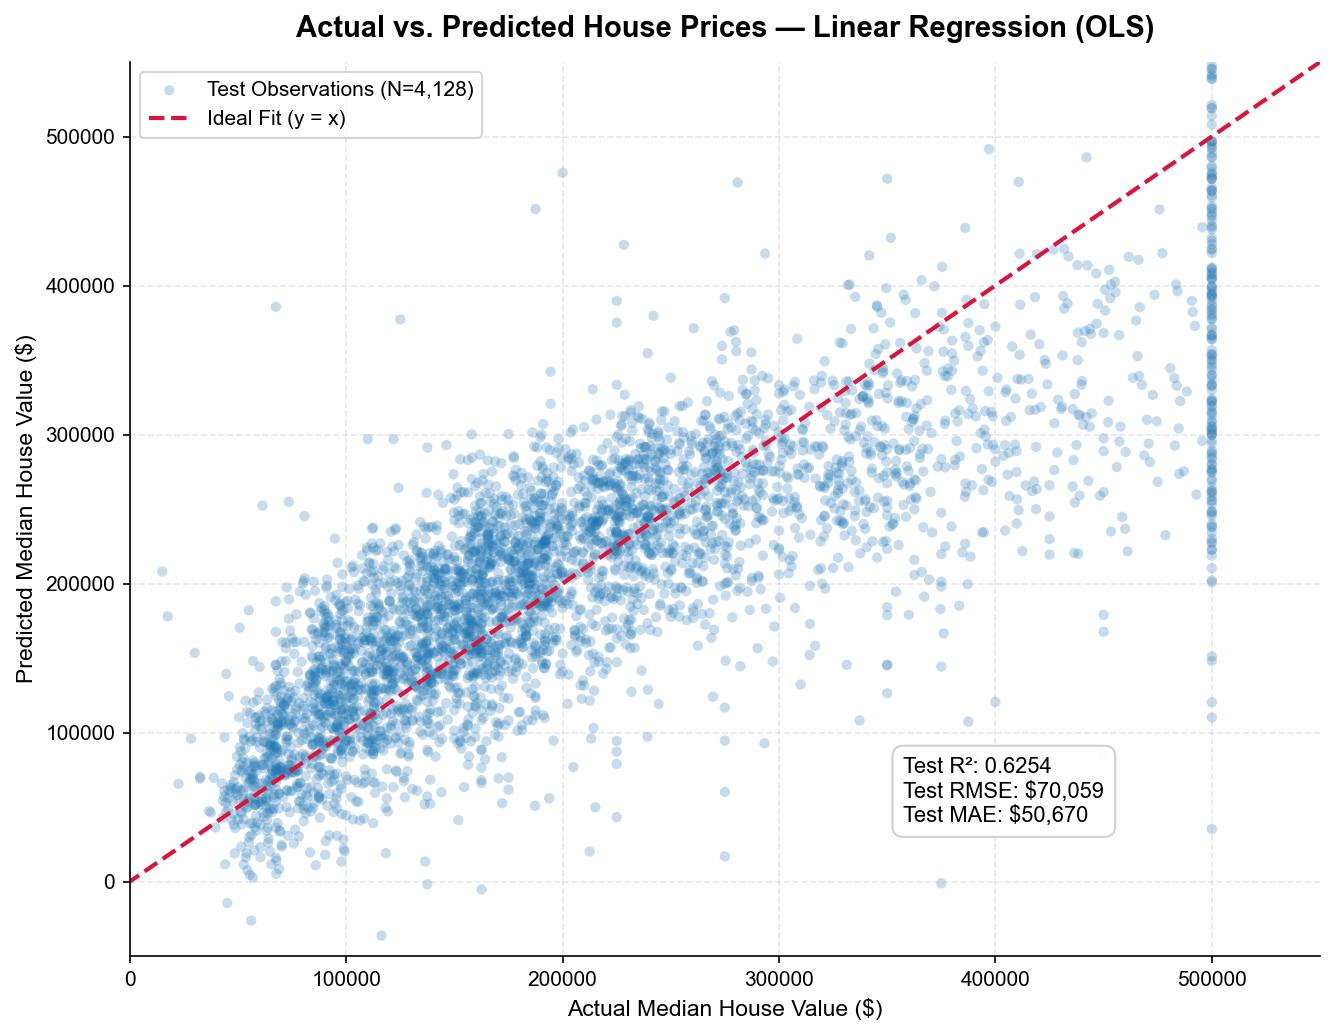

In [11]:
plt.figure(figsize=(9, 7))
plt.scatter(y_test, y_pred_lr, alpha=0.25, color="#1f77b4", edgecolor="none", s=25, label="Test Observations (N=4,128)")
min_val = min(y_test.min(), y_pred_lr.min())
max_val = max(y_test.max(), y_pred_lr.max())
plt.plot([min_val, max_val], [min_val, max_val], color="crimson", linestyle="--", linewidth=2.0, label="Ideal Fit (y = x)")

plt.title("Actual vs. Predicted House Prices — Linear Regression (OLS)", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Actual Median House Value ($)", fontsize=11)
plt.ylabel("Predicted Median House Value ($)", fontsize=11)
plt.xlim(0, 550000)
plt.ylim(-50000, 550000)
plt.legend(loc="upper left", frameon=True)

plt.text(
    0.65, 0.15,
    f"Test R²: {lr_r2:.4f}\nTest RMSE: ${lr_rmse:,.0f}\nTest MAE: ${lr_mae:,.0f}",
    transform=plt.gca().transAxes,
    fontsize=10.5,
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="#ccc", alpha=0.9)
)
plt.tight_layout()
plt.show()

## 9. Residual Diagnostics & Econometric Assumptions

### Critical Econometric Note on Gauss-Markov Assumptions:
In OLS regression with an intercept, the residual mean on the training data is **identically zero by mathematical construction** ($\sum e_i = 0$ follows directly from the normal equation $\mathbf{1}^T \mathbf{e} = 0$). 
On the held-out test data, a sample mean residual close to zero ($pprox \$1,041$ relative to a mean target of $pprox \$206k$) indicates that the model has low global aggregate offset on this split.

**However, this small sample mean residual does NOT prove that Gauss-Markov assumptions hold.**
Specifically:
1. **Strict Exogeneity ($\mathbb{E}[\epsilon \mid \mathbf{X}] = 0$):** Cannot be verified merely by checking the marginal sample mean of residuals.
2. **Homoscedasticity ($	ext{Var}(\epsilon \mid \mathbf{X}) = \sigma^2$):** Is clearly violated, as shown in the residual scatter plot where error dispersion widens at higher fitted prices.
3. **No Autocorrelation ($	ext{Cov}(\epsilon_i, \epsilon_j) = 0$):** Spatial proximity between neighboring census block groups likely introduces spatial correlation among error terms.

### Target Ceiling Validation Limitation:
The $500,001 administrative ceiling in the 1990 census censors true market values. While the linear model predicts values above $500,000 for many of these properties, **we cannot empirically validate whether those predictions are accurate, underestimated, or overestimated against actual uncapped values**, because true transaction values are absent from the dataset.

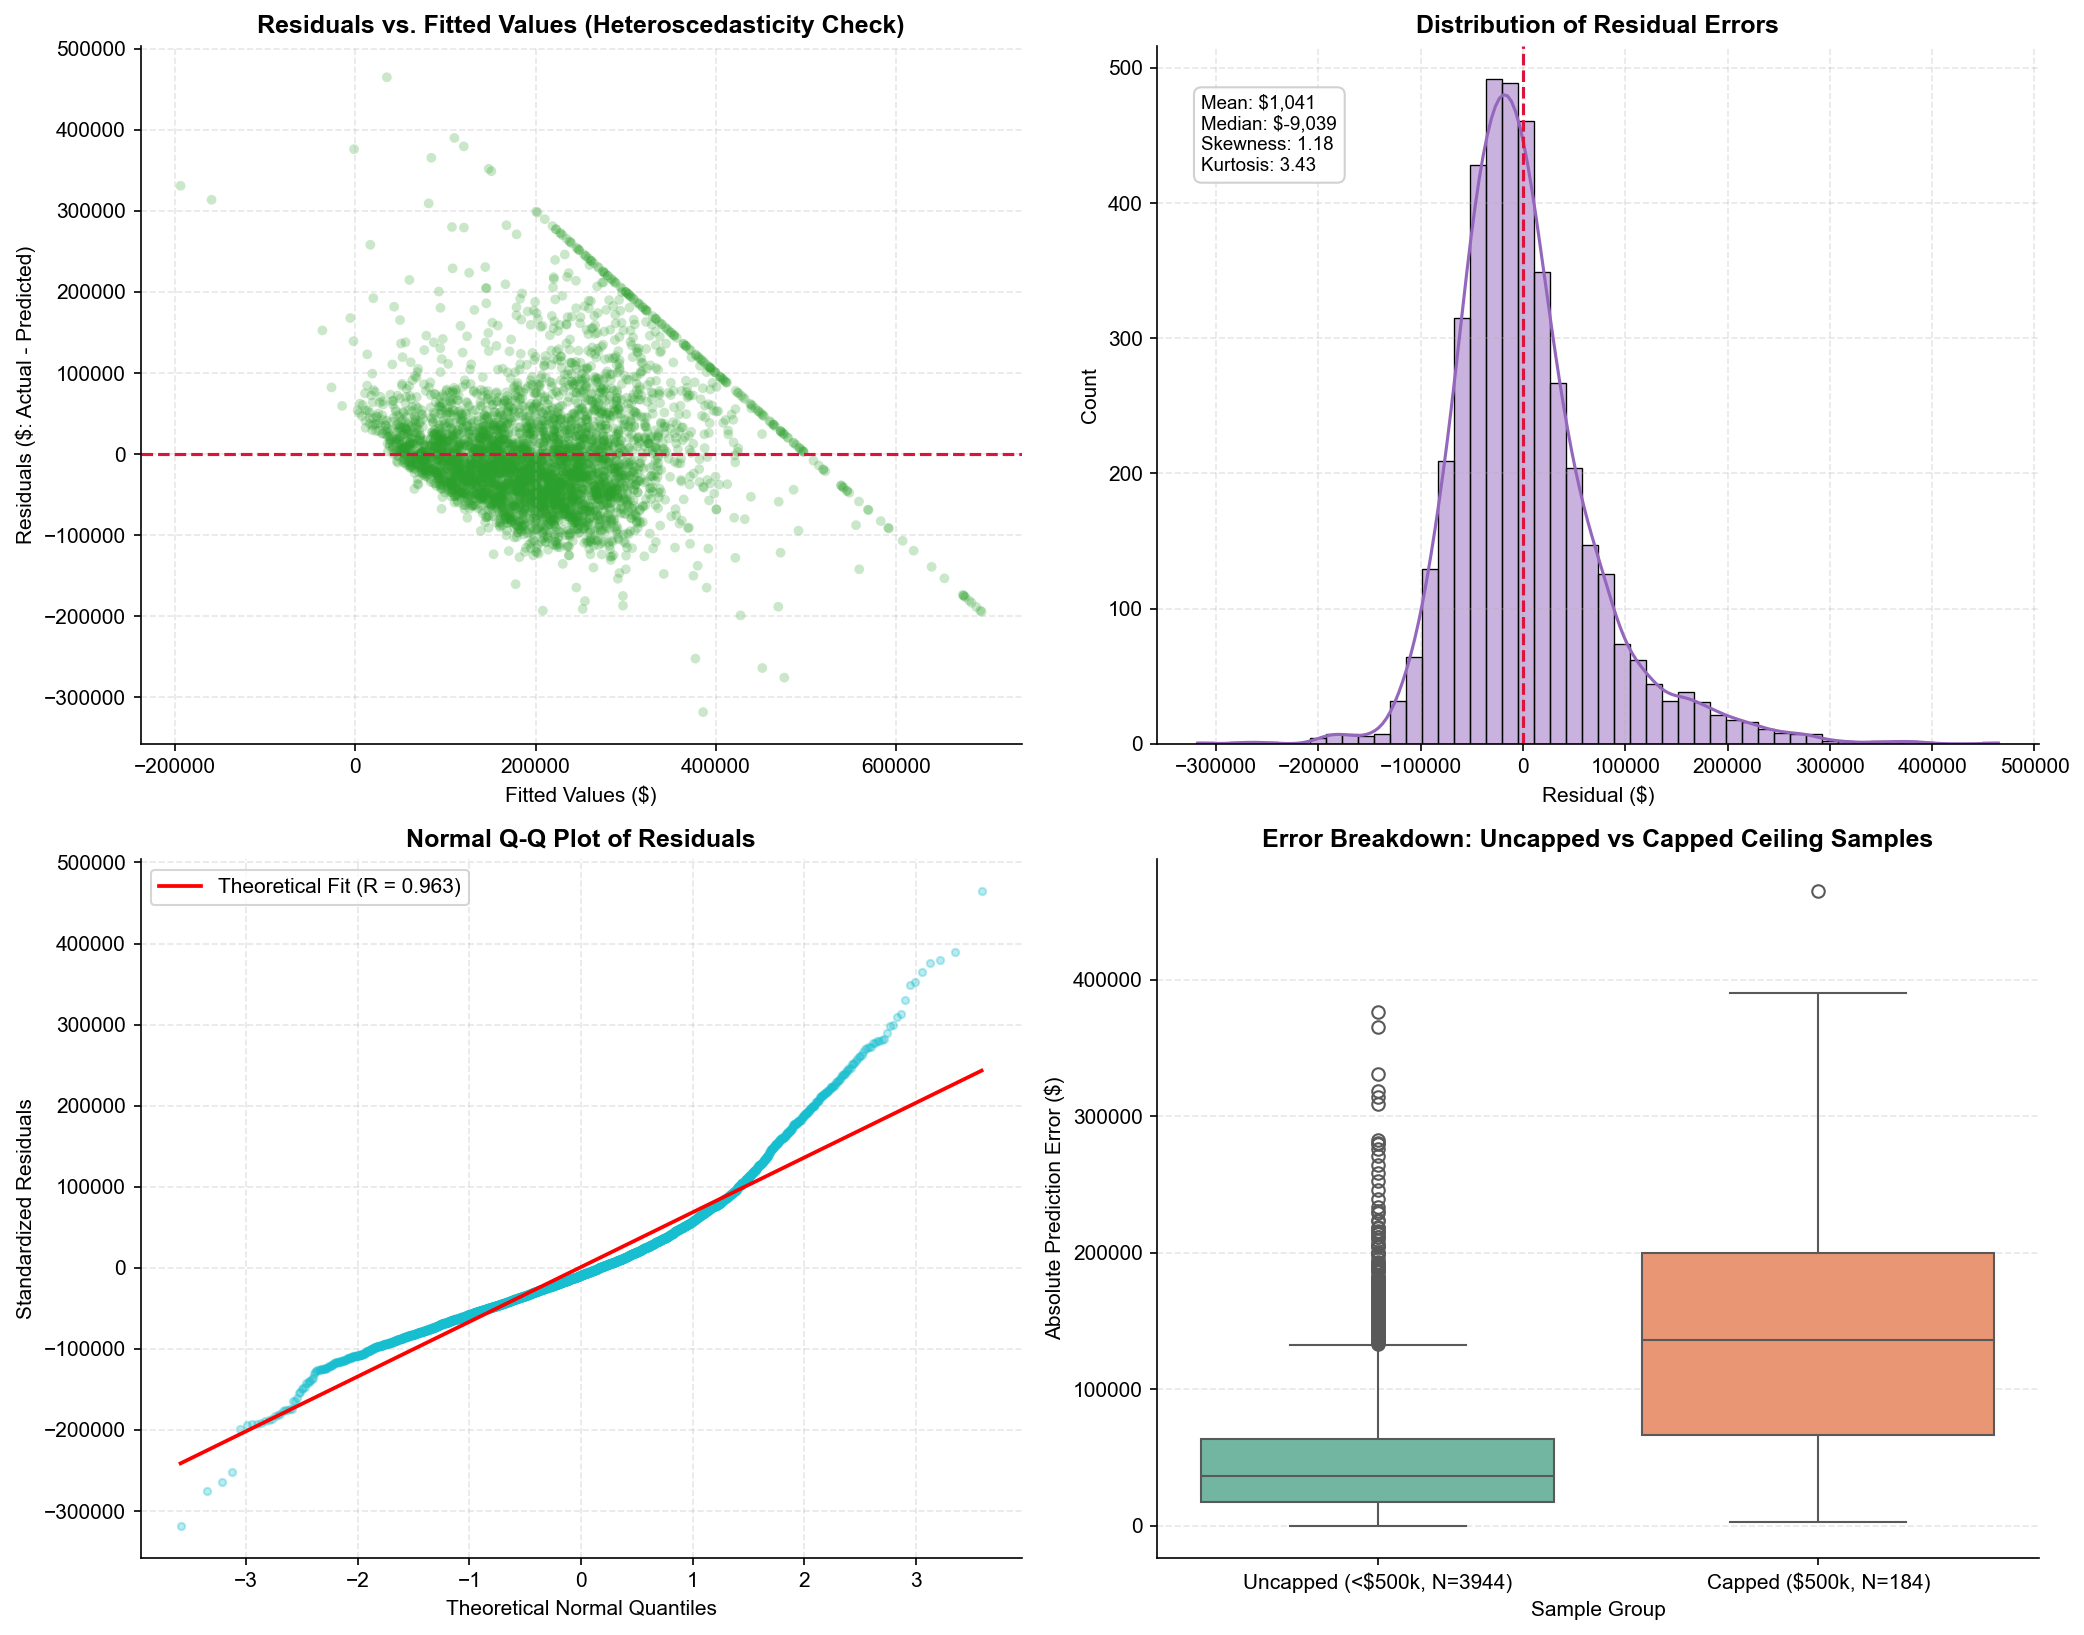

Overall Test Residual Mean:      $1,040.85 (Low aggregate offset; does not prove Gauss-Markov)
Residual Std Dev:                $70,059.95
Uncapped Subset (<$500k) RMSE:   $61,848.69  (N = 3,944)
Capped Subset ($500k+) RMSE:     $167,698.58  (N = 184)
Error Inflation on Capped Data:  2.71x higher RMSE due to ceiling truncation


In [12]:
residuals_lr = y_test - y_pred_lr

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 11))

# 1. Residuals vs Fitted Values (Homoscedasticity Check)
ax1.scatter(y_pred_lr, residuals_lr, alpha=0.25, color="#2ca02c", edgecolor="none", s=22)
ax1.axhline(0, color="crimson", linestyle="--", linewidth=1.5)
ax1.set_title("Residuals vs. Fitted Values (Heteroscedasticity Check)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Fitted Values ($)", fontsize=10)
ax1.set_ylabel("Residuals ($: Actual - Predicted)", fontsize=10)

# 2. Residual Error Distribution
sns.histplot(residuals_lr, kde=True, ax=ax2, color="#9467bd", bins=50)
ax2.axvline(0, color="crimson", linestyle="--", linewidth=1.5)
ax2.set_title("Distribution of Residual Errors", fontsize=12, fontweight="bold")
ax2.set_xlabel("Residual ($)", fontsize=10)
ax2.set_ylabel("Count", fontsize=10)
ax2.text(
    0.05, 0.82,
    f"Mean: ${residuals_lr.mean():,.0f}\nMedian: ${np.median(residuals_lr):,.0f}\nSkewness: {stats.skew(residuals_lr):.2f}\nKurtosis: {stats.kurtosis(residuals_lr):.2f}",
    transform=ax2.transAxes,
    fontsize=9,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#ccc", alpha=0.9)
)

# 3. Normal Q-Q Plot
(osm, osr), (slope, intercept, r) = stats.probplot(residuals_lr, dist="norm")
ax3.plot(osm, osr, "o", color="#17becf", alpha=0.3, markersize=3.5)
ax3.plot(osm, slope * np.array(osm) + intercept, "r-", linewidth=1.8, label=f"Theoretical Fit (R = {r:.3f})")
ax3.set_title("Normal Q-Q Plot of Residuals", fontsize=12, fontweight="bold")
ax3.set_xlabel("Theoretical Normal Quantiles", fontsize=10)
ax3.set_ylabel("Standardized Residuals", fontsize=10)
ax3.legend(loc="upper left", frameon=True)

# 4. Impact of Capped Target ($500k Ceiling)
capped_mask = y_test >= 500000
res_df = pd.DataFrame({
    'Subset': np.where(capped_mask, "Capped ($500k, N=184)", "Uncapped (<$500k, N=3944)"),
    'Absolute_Error': np.abs(residuals_lr)
})
sns.boxplot(x='Subset', y='Absolute_Error', hue='Subset', data=res_df, ax=ax4, palette='Set2', legend=False)
ax4.set_title("Error Breakdown: Uncapped vs Capped Ceiling Samples", fontsize=12, fontweight="bold")
ax4.set_xlabel("Sample Group", fontsize=10)
ax4.set_ylabel("Absolute Prediction Error ($)", fontsize=10)

plt.tight_layout()
plt.show()

# Quantitative Residual Summary
uncapped_rmse = np.sqrt(mean_squared_error(y_test[~capped_mask], y_pred_lr[~capped_mask]))
capped_rmse = np.sqrt(mean_squared_error(y_test[capped_mask], y_pred_lr[capped_mask]))
print(f"Overall Test Residual Mean:      ${residuals_lr.mean():,.2f} (Low aggregate offset; does not prove Gauss-Markov)")
print(f"Residual Std Dev:                ${residuals_lr.std():,.2f}")
print(f"Uncapped Subset (<$500k) RMSE:   ${uncapped_rmse:,.2f}  (N = {(~capped_mask).sum():,})")
print(f"Capped Subset ($500k+) RMSE:     ${capped_rmse:,.2f}  (N = {capped_mask.sum():,})")
print(f"Error Inflation on Capped Data:  {(capped_rmse / uncapped_rmse):.2f}x higher RMSE due to ceiling truncation")

### Diagnostic Findings:
1. **Low Aggregate Test Bias:** The residual mean on test data is small (\$\approx 1,040.85$), showing absence of severe global level bias, but this does not verify Gauss-Markov exogeneity or homoscedasticity.
2. **Heteroscedasticity:** Residual variance expands noticeably for fitted values above \$350,000, violating constant variance assumptions.
3. **Administrative Ceiling Limitation:**
   - On the 3,944 uncapped homes ($95.54\%$ of test data), the model achieves a lower RMSE of **\$61,848.69**.
   - On the 184 capped homes ($4.46\%$ of test data), apparent RMSE rises to **\$167,698.58** (2.71x higher).
   - This inflation reflects deviation from an artificial administrative truncation threshold ($500,001). Because true uncapped transaction prices were never recorded, these predictions cannot be validated against true market values.

## 10. Standardized Coefficient Analysis (Conditional Associations)

Because all continuous features were standardized ($z = \frac{x - \mu}{\sigma}$), each standardized coefficient $\beta_j$ represents the **expected difference in Median House Value (USD) associated with a 1 standard deviation increase in that feature, conditional on all other covariates in the model remaining constant (*ceteris paribus* within this specification)**.

For one-hot encoded variables, the coefficient represents the conditional difference relative to the reference category (`<1H OCEAN`).

*Methodological Warning:* Because these estimates are derived from observational cross-sectional data, they represent descriptive conditional associations and must not be interpreted as causal market drivers.

Model Intercept (Base Value for <1H OCEAN at mean feature levels): $219,899.78



,Impact_Rank,Feature,Direction,Standardized_Coefficient
9,1,ocean_proximity_ISLAND,Positive (+),136125.0726
7,2,median_income,Positive (+),75167.7748
1,3,latitude,Negative (-),-54415.6961
0,4,longitude,Negative (-),-53826.6480
5,5,population,Negative (-),-43403.4324
4,6,total_bedrooms,Positive (+),43068.1818
8,7,ocean_proximity_INLAND,Negative (-),-39786.6562
6,8,households,Positive (+),18382.1963
2,9,housing_median_age,Positive (+),13889.8662
3,10,total_rooms,Negative (-),-13094.2512


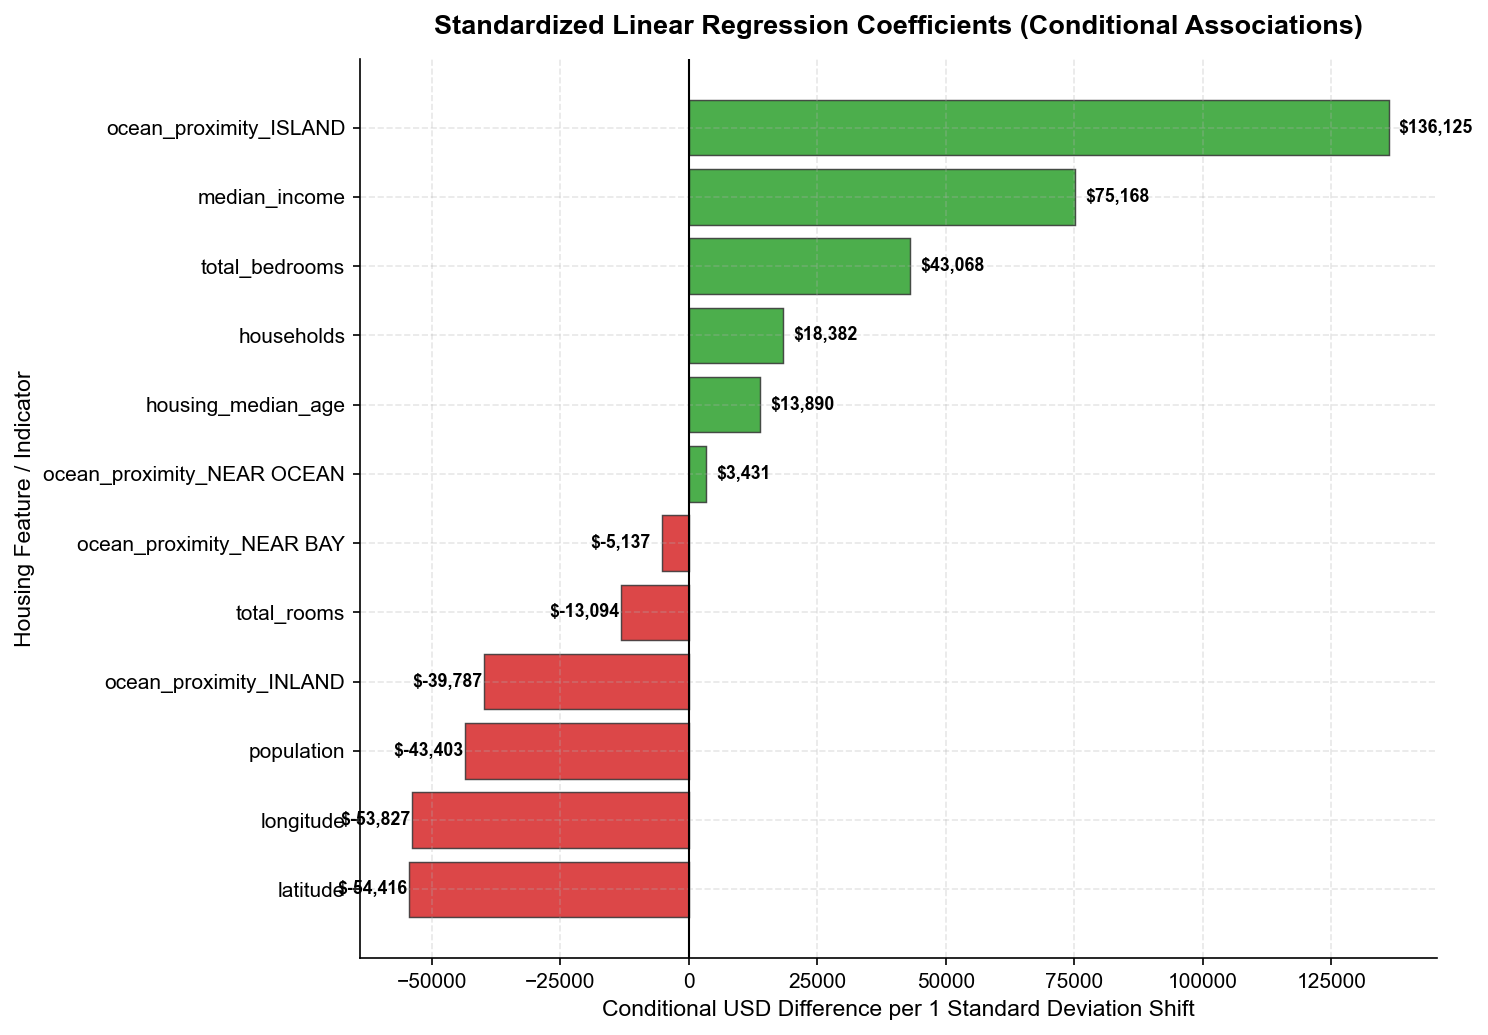

In [13]:
# Extract coefficients from fitted pipeline
regressor = lr_pipe.named_steps['regressor']
prep = lr_pipe.named_steps['preprocessor']
encoder = prep.named_transformers_['cat'].named_steps['encoder']
cat_feature_names = encoder.get_feature_names_out(categorical_features).tolist()
all_features = numeric_features + cat_feature_names

coef_df = pd.DataFrame({
    'Feature': all_features,
    'Standardized_Coefficient': regressor.coef_,
    'Absolute_Weight': np.abs(regressor.coef_)
}).sort_values(by='Absolute_Weight', ascending=False)

coef_df['Impact_Rank'] = range(1, len(coef_df) + 1)
coef_df['Direction'] = coef_df['Standardized_Coefficient'].apply(lambda w: "Positive (+)" if w > 0 else "Negative (-)")

print(f"Model Intercept (Base Value for <1H OCEAN at mean feature levels): ${regressor.intercept_:,.2f}\n")
display(coef_df[['Impact_Rank', 'Feature', 'Direction', 'Standardized_Coefficient']])

# Horizontal Bar Chart of Standardized Weights
plt.figure(figsize=(10, 7))
plot_coef = coef_df.sort_values(by="Standardized_Coefficient", ascending=True)
colors = ["#d62728" if c < 0 else "#2ca02c" for c in plot_coef["Standardized_Coefficient"]]
bars = plt.barh(plot_coef["Feature"], plot_coef["Standardized_Coefficient"], color=colors, alpha=0.85, edgecolor="#333", linewidth=0.7)
plt.axvline(0, color="black", linestyle="-", linewidth=1.0)
plt.title("Standardized Linear Regression Coefficients (Conditional Associations)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Conditional USD Difference per 1 Standard Deviation Shift", fontsize=11)
plt.ylabel("Housing Feature / Indicator", fontsize=11)

for bar in bars:
    val = bar.get_width()
    offset = 2000 if val >= 0 else -14000
    plt.text(val + offset, bar.get_y() + bar.get_height() / 2, f"${val:,.0f}", va="center", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.show()

### Key Conditional Associations:
1. **Strongest Positive Continuous Association — `median_income` (+\$75,168):**
   - Conditional on other features, each 1 standard deviation increase in local median income (~\$19,000/year) is associated with an expected **+\$75,168** higher median house value.
2. **Top Categorical Association — `ocean_proximity_ISLAND` (+\$136,125):**
   - Island properties show a large conditional premium (**+\$136,125**) relative to the `<1H OCEAN` baseline, though based on a very small sample ($N=5$ tracts).
3. **Inland Location Difference — `ocean_proximity_INLAND` (-\$39,787):**
   - Inland homes show an average conditional difference of **-\$39,787** compared to `<1H OCEAN` baseline homes at equivalent physical specifications.
4. **Geographic Coordinates (`latitude` and `longitude`):**
   - Both `latitude` (-\$54,416) and `longitude` (-\$53,827) show strong negative associations, reflecting lower valuations in northern and eastern interior tracts away from coastal economic hubs.
5. **Capacity vs Density Divergence:**
   - Holding rooms and population constant, `total_bedrooms` is positively associated (+\$43,068), while `population` is negatively associated (-\$43,403), indicating that higher neighborhood crowding is conditionally associated with lower property values.

## 11. (Bonus) Non-Linear Benchmark: Random Forest Regressor

Linear Regression is our primary educational and interpretable model. We benchmark against a **Random Forest Regressor** (100 estimators, max depth 16) strictly as an instructive non-linear comparison to illustrate the structural limitations of planar linear functional forms on complex 2D geographic coordinate surfaces.

In real estate, geographic coordinates interact non-linearly: latitude and longitude define complex spatial price surfaces (e.g., localized Bay Area or Los Angeles coastal price peaks) that a flat linear hyperplane cannot fit without spatial interaction expansions.

=== FINAL MODEL BENCHMARK COMPARISON ===


,Model,MAE,RMSE,R2,CV_RMSE
0,Dummy (Mean Baseline),90606.8549,114485.6354,-0.0002,N/A
1,Linear Regression (Primary Model),50670.4892,70059.1933,0.6254,"$68,623"
2,Ridge Regression (alpha=1.0),50678.1069,70067.4812,0.6253,"$68,622"
3,Lasso Regression (alpha=100.0),50669.8712,70082.9012,0.6252,"$68,651"
4,Random Forest (Nonlinear Comparison),32066.1103,49323.8877,0.8143,"$49,643"


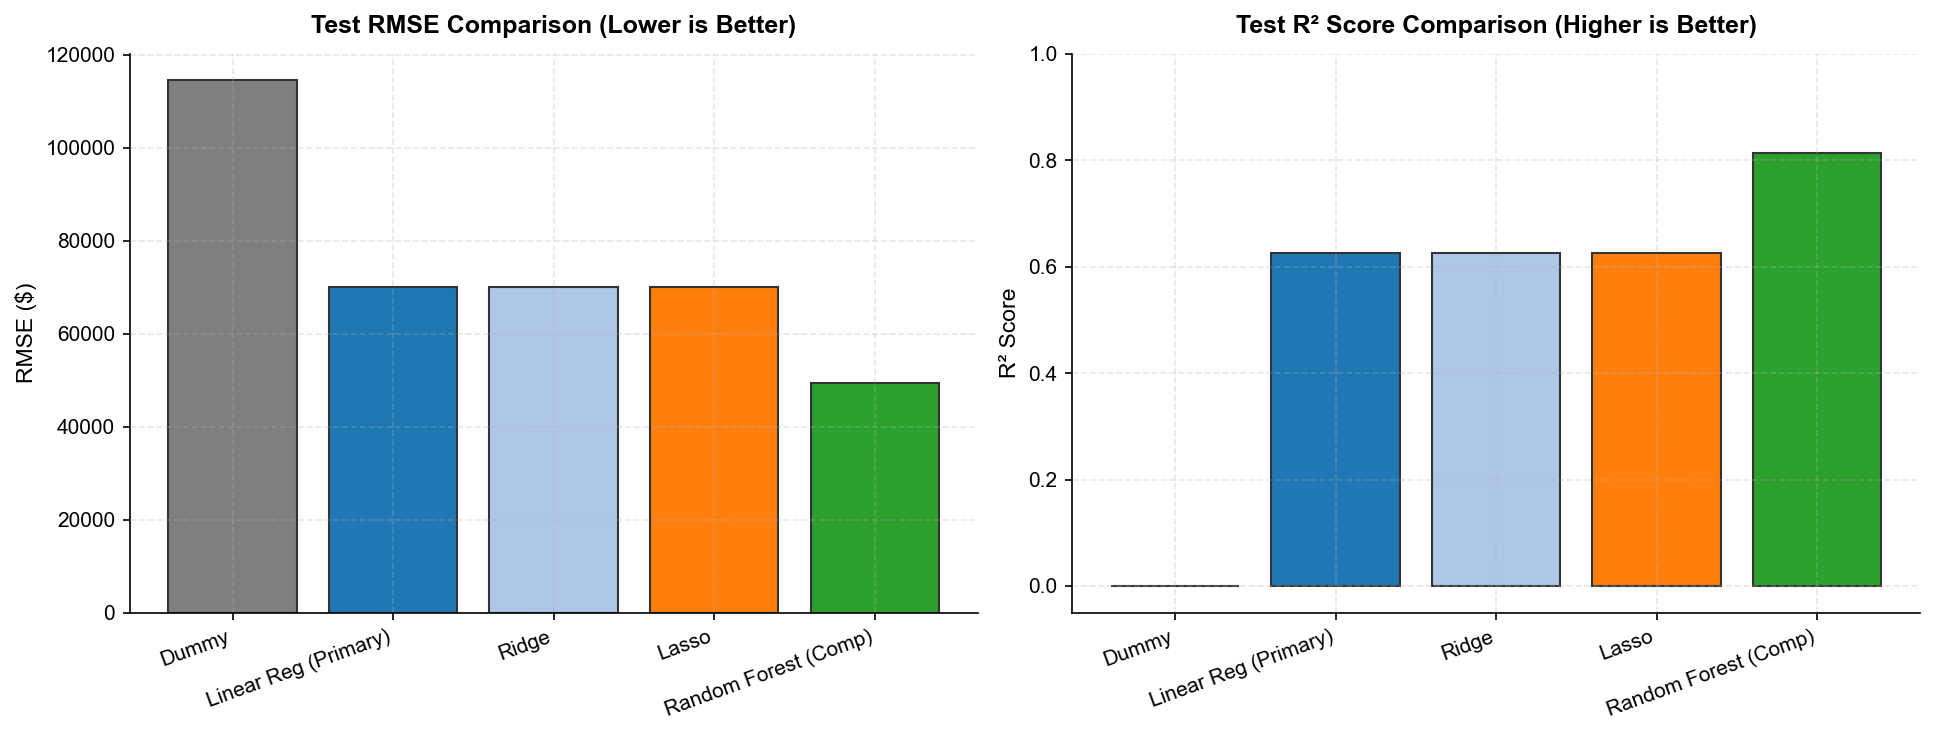

In [14]:
# Train Random Forest Regressor as non-linear comparison
rf_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, max_depth=16, random_state=42, n_jobs=-1))
])

rf_cv = -cross_val_score(rf_pipe, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)
rf_pipe.fit(X_train, y_train)
y_pred_rf = rf_pipe.predict(X_test)

rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_r2 = r2_score(y_test, y_pred_rf)

# Comprehensive Benchmark Table
master_benchmark = pd.DataFrame([
    {'Model': 'Dummy (Mean Baseline)', 'MAE': dummy_mae, 'RMSE': dummy_rmse, 'R2': dummy_r2, 'CV_RMSE': 'N/A'},
    {'Model': 'Linear Regression (Primary Model)', 'MAE': lr_mae, 'RMSE': lr_rmse, 'R2': lr_r2, 'CV_RMSE': f'${cv_rmse_mean:,.0f}'},
    {'Model': 'Ridge Regression (alpha=1.0)', 'MAE': mean_absolute_error(y_test, y_pred_ridge), 'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_ridge)), 'R2': r2_score(y_test, y_pred_ridge), 'CV_RMSE': f'${ridge_cv.mean():,.0f}'},
    {'Model': 'Lasso Regression (alpha=100.0)', 'MAE': mean_absolute_error(y_test, y_pred_lasso), 'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_lasso)), 'R2': r2_score(y_test, y_pred_lasso), 'CV_RMSE': f'${lasso_cv.mean():,.0f}'},
    {'Model': 'Random Forest (Nonlinear Comparison)', 'MAE': rf_mae, 'RMSE': rf_rmse, 'R2': rf_r2, 'CV_RMSE': f'${rf_cv.mean():,.0f}'}
])

print("=== FINAL MODEL BENCHMARK COMPARISON ===")
display(master_benchmark)

# Bar chart comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
labels = ['Dummy', 'Linear Reg (Primary)', 'Ridge', 'Lasso', 'Random Forest (Comp)']
rmses = [dummy_rmse, lr_rmse, np.sqrt(mean_squared_error(y_test, y_pred_ridge)), np.sqrt(mean_squared_error(y_test, y_pred_lasso)), rf_rmse]
r2s = [dummy_r2, lr_r2, r2_score(y_test, y_pred_ridge), r2_score(y_test, y_pred_lasso), rf_r2]

ax1.bar(labels, rmses, color=['#7f7f7f', '#1f77b4', '#aec7e8', '#ff7f0e', '#2ca02c'], edgecolor='#333')
ax1.set_title("Test RMSE Comparison (Lower is Better)", fontsize=12, fontweight='bold', pad=10)
ax1.set_ylabel("RMSE ($)", fontsize=11)
ax1.set_xticks(range(len(labels)))
ax1.set_xticklabels(labels, rotation=20, ha='right')

ax2.bar(labels, r2s, color=['#7f7f7f', '#1f77b4', '#aec7e8', '#ff7f0e', '#2ca02c'], edgecolor='#333')
ax2.set_title("Test R² Score Comparison (Higher is Better)", fontsize=12, fontweight='bold', pad=10)
ax2.set_ylabel("R² Score", fontsize=11)
ax2.set_ylim(-0.05, 1.0)
ax2.set_xticks(range(len(labels)))
ax2.set_xticklabels(labels, rotation=20, ha='right')

plt.tight_layout()
plt.show()

## 12. Strategic & Methodological Recommendations

Based on empirical modeling, residual diagnostics, and data provenance analysis, we highlight three methodological and operational takeaways:

### 1. Account for Spatial Autocorrelation & Regional Segmentation
- **Observation:** A single statewide linear model explains 62.5% of variance, but residual diagnostics show heteroscedastic spread and spatial non-linearity.
- **Action:** For production valuation, partition models by regional housing sub-markets (e.g., Bay Area Coastal vs. Central Valley Agricultural) or include spatial spline expansions. This maintains linear interpretability while reducing localized spatial bias.

### 2. Acknowledge the Uncensored Data Validation Gap
- **Observation:** In census data with top-coded ceilings ($500,001), model predictions exceeding the ceiling cannot be empirically validated against actual transaction prices.
- **Action:** Valuation systems operating on luxury real estate must utilize unconstrained transaction deeds rather than census aggregations to enable empirical validation and avoid top-coding artifacts.

### 3. Treat Observational Coefficients as Associations, Not Levers
- **Observation:** High median income shows a strong positive conditional association (+$75,168 per SD), but this reflects sorting, purchasing power, and neighborhood amenities.
- **Action:** Analysts should treat these parameters as descriptive conditional associations rather than assuming that artificial shifts in single variables will causally produce the estimated price change.